In [13]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

In [14]:
def mostrar(imagens, titulos, cmap='gray', tamanho=4):
  n = len(imagens)
  plt.figure(figsize=(tamanho*n, tamanho))
  for i in range(n):
    plt.subplot(1, n, i + 1)
    plt.imshow(imagens[i], cmap=cmap)
    plt.title(titulos[i])
    plt.axis('off')
  plt.show()

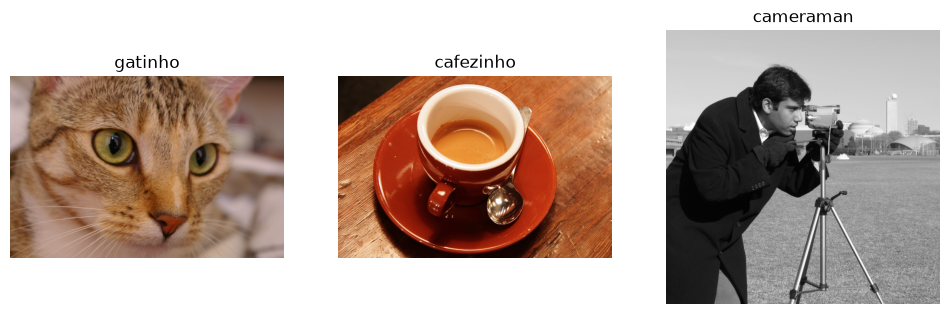

In [15]:
gato = data.cat()
cafe = data.coffee()
camera = data.camera()

mostrar([gato, cafe, camera], ['gatinho', 'cafezinho', 'cameraman'])

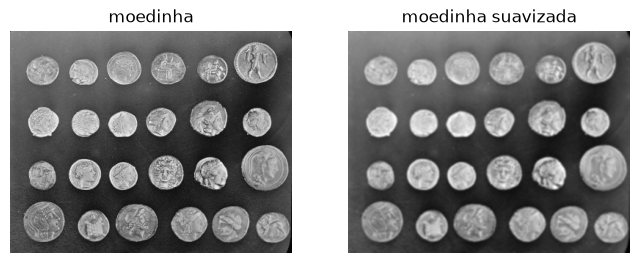

In [16]:
moedas = data.coins()
moedas_suave = cv2.GaussianBlur(moedas, (5,5), 0)

mostrar([moedas, moedas_suave], ['moedinha', 'moedinha suavizada'])

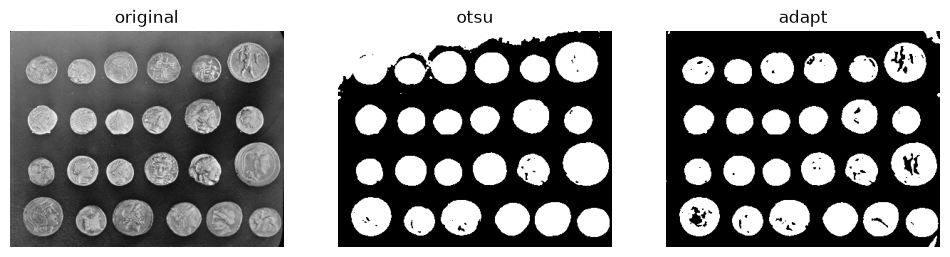

In [17]:
_, moedas_otsu = cv2.threshold(moedas_suave,
                            0,
                            255,
                            cv2.THRESH_OTSU)

moedas_adapt = cv2.adaptiveThreshold(moedas_suave,
                                     255,
                                     cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                     cv2.THRESH_BINARY,
                                     101,
                                     -10)

mostrar([moedas, moedas_otsu, moedas_adapt], ['original', 'otsu', 'adapt'])

In [18]:
contornos, _ = cv2.findContours(moedas_adapt,
                                cv2.RETR_EXTERNAL,
                                cv2.CHAIN_APPROX_SIMPLE)

contornos = [c for c in contornos if cv2.contourArea(c) > 500]
print('Quantidade de contornos', len(contornos))

Quantidade de contornos 24


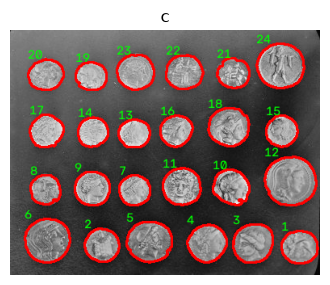

In [19]:
saida = cv2.cvtColor(moedas, cv2.COLOR_GRAY2RGB)
cv2.drawContours(saida, contornos, -1, (255, 0, 0), 2)

for i, c in enumerate(contornos):
  x, y, w, h = cv2.boundingRect(c)
  cv2.putText(saida, str(i+1), (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0))

mostrar([saida], 'contornos')

### Segmentação semântica x segmentação por instância
- Semântica: todos os pixels de moeda recebem a mesma classe (máscara binária).
- Instância: cada moeda recebe um rótulo próprio, então podemos separar os objetos.

In [ ]:
def segmentar(img, bloco=101, c=-10, area_min=500, inv=False):

  suave = cv2.GaussianBlur(img, (5,5), 0)
  tipo = cv2.THRESH_BINARY_INV if inv else cv2.THRESH_BINARY
  binaria = cv2.adaptiveThreshold(suave, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                  tipo, bloco, c)
  contornos, _ = cv2.findContours(binaria, cv2.RETR_EXTERNAL,
                                  cv2.CHAIN_APPROX_SIMPLE)
  contornos = [k for k in contornos if cv2.contourArea(k) > area_min]

  # semântica: tudo que é objeto vira 255 (uma única classe)
  semantica = np.zeros(img.shape, np.uint8)
  cv2.drawContours(semantica, contornos, -1, 255, -1) 

  # instância: cada contorno é preenchido com um rótulo diferente (1, 2, 3...)
  instancia = np.zeros(img.shape, np.int32)
  for i, k in enumerate(contornos):
    cv2.drawContours(instancia, [k], -1, i + 1, -1)

  return contornos, semantica, instancia

In [21]:
def colorir(instancia, seed=3):
  rng = np.random.default_rng(seed)
  cores = rng.integers(60, 256, (instancia.max() + 1, 3)).astype(np.uint8)
  cores[0] = 0
  return cores[instancia]

In [22]:
def comparar(img, semantica, instancia, titulo, tamanho=(12, 4)):
  fig, ax = plt.subplots(1, 3, figsize=tamanho)
  ax[0].imshow(img, cmap='gray')
  ax[0].set_title('original')
  ax[1].imshow(semantica, cmap='gray')
  ax[1].set_title('semântica (1 classe)')
  ax[2].imshow(colorir(instancia))
  ax[2].set_title(f'instância ({instancia.max()} objetos)')
  for a in ax:
    a.axis('off')
  fig.suptitle(titulo)
  plt.show()

### Imagem 1: moedas

Moedas encontradas: 24


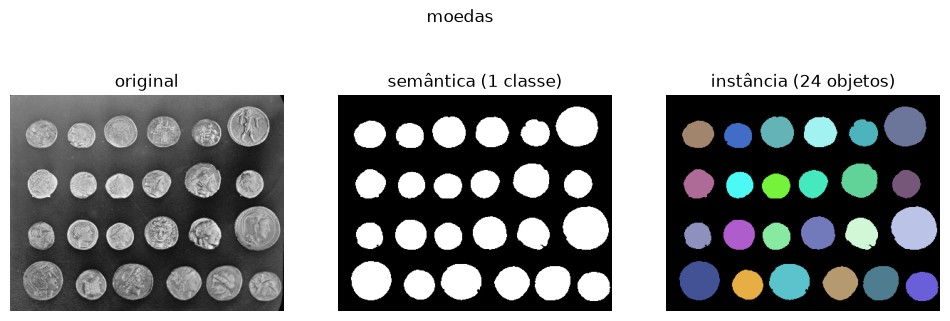

In [23]:
cont_moedas, sem_moedas, inst_moedas = segmentar(moedas, bloco=101, c=-10, area_min=500)
print('Moedas encontradas:', inst_moedas.max())

comparar(moedas, sem_moedas, inst_moedas, 'moedas')

### Imagem 2: página de texto
Aqui o texto é escuro sobre fundo claro, então usamos `inv=True` (THRESH_BINARY_INV).

Objetos encontrados: 95


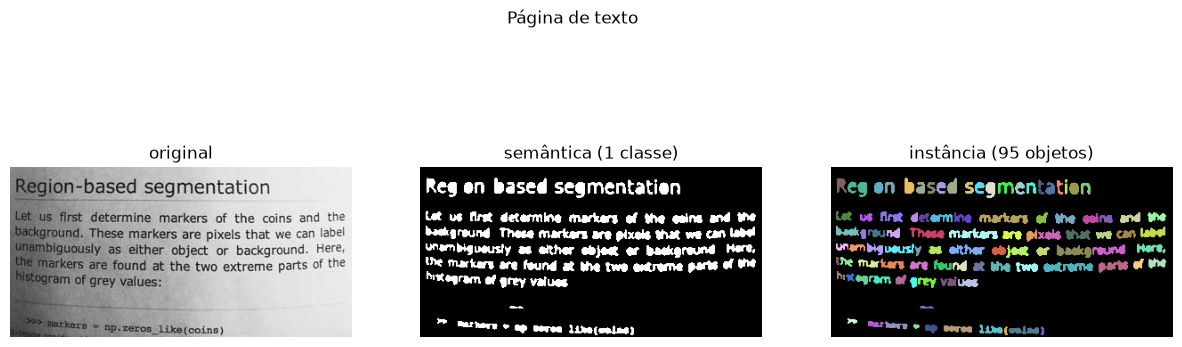

In [24]:
pagina = data.page()

cont_pag, sem_pag, inst_pag = segmentar(pagina, bloco=31, c=10, area_min=15, inv=True)
print('Objetos encontrados:', inst_pag.max())

comparar(pagina, sem_pag, inst_pag, 'Página de texto', tamanho=(15, 5))

### Análise
Moedas: a semântica só diz onde há moeda, todas ficam brancas. A instância separa as 24 moedas, uma cor para cada, e ela reconhece que cada contorno é uma moeda.

Página: a semântica mostra todo o texto como uma só classe. Na instância, o resultado não são letras individuais: letras coladas ou muito próximas viram um único contorno e pedaços pequenos se perdem. Portanto, na imagem das moedas a instância bate com os objetos reais, na página, não, porque os objetos se encostam e acabam confundindo a limiarização.